# Notebook 27 · Auditoría de sistemas minerales y comparación controlada

Este cuaderno ejecuta los **puntos 1 a 4 de la revisión del NB26** y reentrena los modelos nacionales. Conserva las entradas y resultados anteriores.

1. Revisar las tipologías: sin provincia como sustituto de sistema mineral, sin asignar los desconocidos a roca y conservando casos mixtos.
2. Auditar la geoquímica: distinguir representantes de intervalos de mediciones analíticas; conservar ausentes y ajustar las estadísticas aprendidas solo dentro de entrenamiento.
3. Revisar la mezcla: normalización de fondo aprendida dentro de entrenamiento y pesos elegidos mediante CV interna; sin factor 0,7 ni mínimos/máximos del test.
4. Comparar global93/global95, dos y tres especialistas, máximo/fusión aprendida, una regla geológica predefinida y selección aleatoria. Reentrenar y guardar todos los modelos y sus mapas.

**Diseño exploratorio interno:** se reutilizan territorios ya examinados en NB19–26. Aunque cada ajuste excluye su evaluación, esta ejecución no constituye una campaña externa nueva ni acredita probabilidades físicas de encontrar oro. No se añaden las nuevas fuentes o el piloto de los puntos 5–6.

Implementación reproducible: `src/geoau/controlled_system_features.py`, `controlled_system_models.py` y `controlled_system_experiment.py`. Las celdas siguientes ejecutan sus etapas y muestran los datos, métricas y visualizaciones obtenidos realmente.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown

ROOT = Path.cwd().resolve()
if not (ROOT / 'src').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
from geoau.controlled_system_experiment import ControlledExperiment
from geoau.controlled_system_models import BackgroundCDF, FAMILIES, METHODS

exp = ControlledExperiment(ROOT, output='reports/nb27_comparacion_controlada_20261022')
print('Python:', sys.executable)
print('Repositorio:', ROOT)
print('Resultados:', exp.output)
print('Dominio:', len(exp.data.grid), '| P:', len(exp.data.positives))


2026-10-21T22:47:32+00:00 Experimento NB27 iniciado: 5 CV + 7 rotaciones + ajuste nacional; configuración fijada


Python: C:\Users\Lenovo\Desktop\PROYECTO IA\GeoAI\GeoAI\.venv-fase-a\Scripts\python.exe
Repositorio: C:\Users\Lenovo\Desktop\PROYECTO IA\GeoAI\GeoAI
Resultados: C:\Users\Lenovo\Desktop\PROYECTO IA\GeoAI\GeoAI\reports\nb27_comparacion_controlada_20261022
Dominio: 478443 | P: 664


## 1. Revisión operativa de tipologías

Se utiliza `tipo_au_revisado` y la identificación documentada de los depósitos de Rodalquilar. **Primario no significa exclusivamente orogénico**: incluye contextos de roca no separados con suficiente evidencia. La regla epitermal se limita a `dep_rodalquilar_cinto` y `dep_rodalquilar_santa_josefa`, con la documentación ya contenida en el inventario. Esto no sustituye una nueva certificación geológica.

Los pendientes conservan su peso 0,5 y las confirmadas peso 1. Las P de sistema desconocido se conservan en los modelos globales y en el componente global de las fusiones, sin imputarles una génesis. Una celda de 1 km puede conservar varias tipologías documentadas. Las tablas por registro incluyen evidencia, motivo y regla aplicada.

In [2]:
tipologias = exp.audit_labels()
display(tipologias)
auditoria_registros = pd.read_csv(exp.output / 'auditoria_sistemas_por_registro.csv')
display(auditoria_registros.loc[auditoria_registros.epitermal,
    ['Nombre_mina', 'deposit_id', 'tipo_au_revisado', 'regla_sistema', 'evidencia']])
display(exp.systems.loc[exp.systems.mixto | exp.systems.no_resuelto].head(12))


2026-10-21T22:47:32+00:00 Auditoría de tipologías: [{"grupo":"primario","celdas_P":263},{"grupo":"primario_otro","celdas_P":259},{"grupo":"aluvial","celdas_P":310},{"grupo":"epitermal","celdas_P":4},{"grupo":"no_resuelto","celdas_P":98},{"grupo":"mixto","celdas_P":7}]


,grupo,celdas_P
0,primario,263
1,primario_otro,259
2,aluvial,310
3,epitermal,4
4,no_resuelto,98
5,mixto,7


,Nombre_mina,deposit_id,tipo_au_revisado,regla_sistema,evidencia
741,MINA SANTA JOSEFA,dep_rodalquilar_santa_josefa,roca,deposito_documentado_Rodalquilar,Arribas et al. (1995) Econ. Geol. 90:795-822 (...
742,LABORES MERIDIONALES DE RODALQUILAR,dep_rodalquilar_cinto,roca,deposito_documentado_Rodalquilar,Hernández et al. (1989) Bol. Geol. Min. 100:75...
743,CANTERA DEL CERRO MADRIGUERAS,dep_rodalquilar_cinto,roca,deposito_documentado_Rodalquilar,Arribas et al. (1995) Econ. Geol. 90:795-822 (...
744,GRAN CANTERA OCCIDENTAL DEL SUR DEL CERRO DEL ...,dep_rodalquilar_cinto,roca,deposito_documentado_Rodalquilar,Arribas et al. (1995) Econ. Geol. 90:795-822 (...
745,CERRO DEL CINTO SE.1,dep_rodalquilar_cinto,roca,deposito_documentado_Rodalquilar,Arribas et al. (1995) Econ. Geol. 90:795-822 (...
746,GRAN CANTERA ORIENTAL DEL SUR DEL CERRO DEL CINTO,dep_rodalquilar_cinto,roca,deposito_documentado_Rodalquilar,Arribas et al. (1995) Econ. Geol. 90:795-822 (...
747,CERRO DEL CINTO SE.2,dep_rodalquilar_cinto,roca,deposito_documentado_Rodalquilar,Arribas et al. (1995) Econ. Geol. 90:795-822 (...
748,CERRO DEL CINTO E.,dep_rodalquilar_cinto,roca,deposito_documentado_Rodalquilar,Arribas et al. (1995) Econ. Geol. 90:795-822 (...


,cell_id,peso_confianza,n_records,primario,aluvial,epitermal,primario_otro,no_resuelto,mixto,epitermal_y_aluvial
2,es_pen_utm30_1km_v1_r0033_c0242,0.5,1,False,False,False,False,True,False,False
3,es_pen_utm30_1km_v1_r0033_c0244,0.5,1,False,False,False,False,True,False,False
6,es_pen_utm30_1km_v1_r0035_c0239,0.5,1,False,False,False,False,True,False,False
7,es_pen_utm30_1km_v1_r0036_c0240,0.5,1,False,False,False,False,True,False,False
8,es_pen_utm30_1km_v1_r0037_c0239,0.5,1,False,False,False,False,True,False,False
9,es_pen_utm30_1km_v1_r0037_c0240,0.5,2,False,False,False,False,True,False,False
12,es_pen_utm30_1km_v1_r0037_c0272,0.5,1,False,False,False,False,True,False,False
13,es_pen_utm30_1km_v1_r0038_c0272,0.5,1,False,False,False,False,True,False,False
14,es_pen_utm30_1km_v1_r0039_c0238,0.5,1,False,False,False,False,True,False,False
16,es_pen_utm30_1km_v1_r0039_c0270,0.5,1,False,False,False,False,True,False,False


## 2. Auditoría de geoquímica y construcción de covariables

Se inspecciona la banda 2, sus valores distintos y su relación con las clases. **Un representante numérico por intervalo no es una concentración analítica continua original.** Promediar 2 × 2 píxeles y aplicar log1p no crea mediciones nuevas. Se conserva esta representación con nombres y limitaciones explícitos.

La matriz tiene 95 variables; la versión de 93 excluye únicamente `trampa_valle_aluvial` y `vector_epitermal_hidrotermal`. Ambas comparten las correcciones. `grado_metamorfico` y `afinidad_esquistos_verdes` se documentan como proxies heurísticos litológicos, no como mediciones de facies metamórfica.

Se reconstruyen los cuatro indicadores MODIS desde las teselas ya descargadas para retirar el relleno por mediana nacional anterior. No se adquiere otro sensor ni se aplica una nueva máscara QA. Los residuos de ventana fija son covariables cartográficas sin etiquetas. Las medianas, escalado, categorías y estadísticas empíricas globales del índice pathfinder se aprenden **por miembro, solo con sus filas de entrenamiento**.

Para obtener analítica continua real hace falta una fuente con mediciones o valores originales; el cuaderno no la inventa a partir de las clases.

In [3]:
auditoria_geoquimica = exp.prepare_features()
display(auditoria_geoquimica)
display(pd.read_csv(exp.output / 'representantes_clases_geoquimicas.csv').head(16))
contrato = pd.read_csv(exp.output / 'contrato_variables.csv')
print('Variables global93:', int(contrato.incluida_93.sum()), '| global95:', len(contrato))
display(exp.X[['trampa_valle_aluvial', 'vector_epitermal_hidrotermal']].describe())
print('Ausentes retenidos en representantes geoquímicos:')
display(exp.X.filter(like='representante_intervalo').isna().sum().to_frame('celdas_sin_dato'))


2026-10-21T22:47:32+00:00 Auditando los ocho rásteres y reconstruyendo covariables MODIS desde la caché


2026-10-21T22:48:07+00:00 Matriz corregida disponible: 478443 celdas x 95 variables


,elemento,banda,unidades_etiquetadas,valores_distintos_500m,un_valor_por_clase,mediciones_analiticas_continuas,fraccion_ausente_500m
0,AS,As_Sedimento_Concentracion_ppm_mid,mg/kg (ppm),8,True,False,0.508138
1,SB,Sb_Sedimento_Concentracion_ppm_mid,mg/kg (ppm),8,True,False,0.509645
2,BI,Bi_Sedimento_Concentracion_ppm_mid,mg/kg (ppm),8,True,False,0.508138
3,HG,Hg_Sedimento_Concentracion_mid_ppb (ng/g),ppb (ng/g),8,True,False,0.508138
4,CU,Cu_Sedimento_Concentracion_mid_mg/kg (ppm),mg/kg (ppm),8,True,False,0.508138
5,W,W_Sedimento_Concentracion_mid_mg/kg (ppm),mg/kg (ppm),7,True,False,0.508138
6,PB,Pb_Sedimento_Concentracion_mid_mg/kg (ppm),mg/kg (ppm),8,True,False,0.508516
7,ZN,Zn_Sedimento_Concentracion_mid_mg/kg (ppm),mg/kg (ppm),8,True,False,0.508138


,elemento,clase,representante_intervalo
0,AS,0,0.600000
1,AS,1,5.230000
2,AS,2,7.260000
3,AS,3,10.550000
4,AS,4,14.310000
5,AS,5,17.940001
6,AS,6,29.930000
7,AS,7,296.220001
8,SB,0,0.098800
9,SB,1,0.372900


Variables global93: 93 | global95: 95


,trampa_valle_aluvial,vector_epitermal_hidrotermal
count,4.652400e+05,477793.000000
mean,5.544997e-02,0.335252
std,1.340733e-01,0.104794
min,6.674300e-17,0.084867
25%,7.124079e-06,0.295196
50%,9.040131e-04,0.325470
75%,2.761823e-02,0.359893
max,9.938675e-01,5.088456


Ausentes retenidos en representantes geoquímicos:


,celdas_sin_dato
geoq_as_representante_intervalo_log,3101
geoq_sb_representante_intervalo_log,4200
geoq_bi_representante_intervalo_log,3101
geoq_hg_representante_intervalo_log,3101
geoq_cu_representante_intervalo_log,3101
geoq_w_representante_intervalo_log,3101
geoq_pb_representante_intervalo_log,2730
geoq_zn_representante_intervalo_log,3101


## 3. Mezcla ajustada dentro del entrenamiento

Cada componente utiliza ocho LightGBM con muestreo U independiente **sin reemplazo** y tres U por P. El muestreo parte del territorio autorizado, tanto para entrenamiento interno y externo como para el mapa final. Global93 y global95 comparten exactamente P, U, pesos, semillas e hiperparámetros; los componentes comunes de las arquitecturas se reutilizan.

En cada entrenamiento externo:

1. Se construyen tres pliegues espaciales internos por bloques de 50 km y buffer de 15 km.
2. Se generan predicciones internas OOF de cada componente.
3. Se ajustan referencias de fondo con las predicciones U internas. La normalización usa rangos medios interpolados y anclas fijas 0/1; no depende de qué otras celdas se puntúen después.
4. Con referencias de fondo cruzadas entre los pliegues internos se eligen pesos no negativos que maximizan AP interna. El componente global conserva peso mínimo 0,1. Los pesos y las referencias se fijan antes de predecir el territorio externo.

`max_2`/`fusion_2`: global95 + primario + aluvial. `max_3`/`fusion_3`: global95 + primario_otro + aluvial + epitermal. Máximo y fusión usan **exactamente los mismos componentes**. La diferencia es el operador de agregación. Si hay menos de dos P de un especialista se marca no disponible; no se fabrica un modelo ni se sustituye por una regla adaptada al test.

El especialista epitermal tiene una capacidad reducida predeclarada por su escasez. Las comparaciones de los componentes comunes conservan su configuración. Los scores normalizados expresan rareza frente al fondo, **no probabilidades de depósito**.

In [4]:
display(pd.Series(exp.cfg, name='Diseño fijado antes de evaluar').to_frame())
display(pd.DataFrame([{'metodo': k, 'componentes': ' + '.join(v)} for k,v in FAMILIES.items()]))

# Demostración de invariancia: añadir otra celda al lote no cambia el score de la primera.
cdf = BackgroundCDF().fit(np.array([0.1, 0.2, 0.3, 0.4]))
assert cdf.transform([0.25])[0] == cdf.transform([0.25, 0.99])[0]
print('Normalización independiente del lote de predicción: verificada')


,Diseño fijado antes de evaluar
seed,42
bags,8
inner_folds,3
buffer_m,15000
weight_step,0.1
minimum_specialist_P,2
prediction_batch_size,25000
default_national_method,fusion_3
selection_metric,inner_oof_average_precision
classifier,"{'n_estimators': 150, 'max_depth': 5, 'num_lea..."


,metodo,componentes
0,fusion_2,mono95 + primario + aluvial
1,fusion_3,mono95 + primario_otro + aluvial + epitermal


Normalización independiente del lote de predicción: verificada


## 4. Comparación controlada y reentrenamiento

Las métricas se generan desde predicciones y CSV, sin escribir manualmente los resultados de la tabla. Se reutilizan las cinco particiones espaciales originales para métricas P/U y las siete reservas distritales para recuperación de depósitos. Bloques de 50 km, buffer de 15 km y presupuestos exactos con desempate por cell_id.

El contraste global93/global95 aísla los dos descriptores nuevos bajo un procedimiento común corregido. Las comparaciones 2/3 expertos estudian la partición de tipologías y arquitectura. Máximo/fusión compara la agregación de los mismos modelos. El resultado histórico del NB26 tiene otra preparación y mezcla: se conserva como antecedente, no como control causal equivalente.

**Las medias OOF globales no son una media simple de las métricas por pliegue.** Brier se calcula frente a P/U y, para scores de rareza, es solo un diagnóstico numérico; no acredita calibración ni sirve para comparar probabilidades físicas.

In [5]:
metricas_cv = exp.evaluate_cv()
display(metricas_cv)
display(pd.read_csv(exp.output / 'cv_fold_metrics.csv'))


2026-10-21T22:48:08+00:00 Comenzando cv/0: 450 P, 503 celdas a puntuar


2026-10-21T22:48:29+00:00 cv 0 inner_0: P=358, especialistas={'primario': 86, 'aluvial': 223, 'primario_otro': 86, 'epitermal': 0}, 40 ajustes declarados, 6.4s


2026-10-21T22:48:38+00:00 cv 0 inner_1: P=212, especialistas={'primario': 95, 'aluvial': 97, 'primario_otro': 95, 'epitermal': 0}, 40 ajustes declarados, 4.7s


2026-10-21T22:48:46+00:00 cv 0 inner_2: P=109, especialistas={'primario': 43, 'aluvial': 59, 'primario_otro': 43, 'epitermal': 0}, 40 ajustes declarados, 3.4s


2026-10-21T22:48:57+00:00 cv 0 outer: P=450, especialistas={'primario': 128, 'aluvial': 270, 'primario_otro': 128, 'epitermal': 0}, 40 ajustes declarados, 7.0s


...

2026-10-21T22:52:02+00:00 cv 4 inner_2: P=249, especialistas={'primario': 58, 'aluvial': 161, 'primario_otro': 58, 'epitermal': 0}, 40 ajustes declarados, 5.1s


2026-10-21T22:52:13+00:00 cv 4 outer: P=444, especialistas={'primario': 174, 'aluvial': 193, 'primario_otro': 174, 'epitermal': 0}, 40 ajustes declarados, 6.7s


2026-10-21T22:52:14+00:00 CV 5/5 terminada; AUC mono95=0.8748


,method,roc_auc,average_precision,pr_auc_trapezoid,brier_loss,positive_cell_recovery_at_01,positive_cell_recovery_at_05,positive_cell_recovery_at_10
0,mono93,0.894144,0.698035,0.697298,0.131120,0.031797,0.160572,0.310016
1,mono95,0.894895,0.702020,0.701309,0.130762,0.031797,0.157393,0.311606
2,max_2,0.889989,0.687164,0.686484,0.322410,0.034976,0.160572,0.313196
3,fusion_2,0.894097,0.699863,0.698879,0.255517,0.031797,0.155803,0.310016
4,max_3,0.889989,0.687164,0.686484,0.322410,0.034976,0.160572,0.313196
5,fusion_3,0.894097,0.699863,0.698879,0.255517,0.031797,0.155803,0.310016
6,regla_geologica,0.785134,0.453527,0.452109,0.197576,0.014308,0.082671,0.186010


,method,fold,n_train_P,roc_auc,average_precision,pr_auc_trapezoid,brier_loss,positive_cell_recovery_at_01,positive_cell_recovery_at_05,positive_cell_recovery_at_10
0,mono93,0,450,0.902414,0.670470,0.667844,0.127055,0.046296,0.185185,0.333333
1,mono95,0,450,0.908650,0.689068,0.686611,0.123113,0.046296,0.175926,0.342593
2,max_2,0,450,0.901899,0.664570,0.662105,0.308738,0.055556,0.185185,0.324074
3,fusion_2,0,450,0.908650,0.689068,0.686611,0.251041,0.046296,0.175926,0.342593
4,max_3,0,450,0.901899,0.664570,0.662105,0.308738,0.055556,0.185185,0.324074
5,fusion_3,0,450,0.908650,0.689068,0.686611,0.251041,0.046296,0.175926,0.342593
6,regla_geologica,0,450,0.822152,0.492262,0.485922,0.164833,0.009259,0.120370,0.250000
7,mono93,1,480,0.945958,0.819430,0.816639,0.087196,0.033898,0.203390,0.355932
8,mono95,1,480,0.945847,0.823337,0.821260,0.086700,0.033898,0.203390,0.355932
9,max_2,1,480,0.936751,0.760709,0.756988,0.333081,0.033898,0.177966,0.347458


### 4.1. Recuperación territorial y referencias

Se puntúan todas las celdas de cada reserva y se cuenta una vez cada depósito representado en la selección. La referencia aleatoria utiliza la probabilidad exacta de seleccionar al menos una de las celdas de cada depósito con el mismo presupuesto; no supone que un depósito ocupe una sola celda. La regla geológica es una referencia física simple predefinida, sin ajuste al test.

In [6]:
metricas_rotaciones = exp.evaluate_rotations()
display(metricas_rotaciones[['method', 'n_deposits', 'captured_01', 'captured_05', 'captured_10', 'captured_20']])
display(pd.read_csv(exp.output / 'random_summary.csv'))
display(pd.read_csv(exp.output / 'rotation_metrics.csv'))


2026-10-21T22:52:15+00:00 Comenzando rotation/0: 559 P, 9290 celdas a puntuar


2026-10-21T22:52:40+00:00 rotation 0 inner_0: P=198, especialistas={'primario': 126, 'aluvial': 53, 'primario_otro': 122, 'epitermal': 4}, 48 ajustes declarados, 6.2s


2026-10-21T22:52:52+00:00 rotation 0 inner_1: P=348, especialistas={'primario': 112, 'aluvial': 196, 'primario_otro': 112, 'epitermal': 0}, 40 ajustes declarados, 6.4s


2026-10-21T22:53:05+00:00 rotation 0 inner_2: P=325, especialistas={'primario': 108, 'aluvial': 189, 'primario_otro': 104, 'epitermal': 4}, 48 ajustes declarados, 7.2s


2026-10-21T22:53:23+00:00 rotation 0 outer: P=559, especialistas={'primario': 202, 'aluvial': 294, 'primario_otro': 198, 'epitermal': 4}, 48 ajustes declarados, 11.6s


...

2026-10-21T22:59:59+00:00 rotation 6 outer: P=516, especialistas={'primario': 214, 'aluvial': 241, 'primario_otro': 214, 'epitermal': 0}, 40 ajustes declarados, 9.4s


2026-10-21T22:59:59+00:00 Rotación 7/7 terminada


,method,n_deposits,captured_01,captured_05,captured_10,captured_20
0,mono93,45,1,4,11,16
1,mono95,45,1,5,10,16
2,max_2,45,1,6,11,17
3,fusion_2,45,0,6,10,15
4,max_3,45,1,9,12,20
5,fusion_3,45,0,7,10,15
6,regla_geologica,45,1,9,10,15


,budget_percent,expected_deposits
0,1,1.315466
1,5,6.160566
2,10,11.434624
3,20,19.909472


,method,group,n_deposits,n_held_cells,captured_deposits_at_01,deposit_recovery_at_01,recovery_at_01,captured_deposits_at_05,deposit_recovery_at_05,recovery_at_05,captured_deposits_at_10,deposit_recovery_at_10,recovery_at_10,captured_deposits_at_20,deposit_recovery_at_20,recovery_at_20
0,mono93,0,7,9290,0,0.000000,0.000000,0,0.000000,0.000000,1,0.142857,0.142857,2,0.285714,0.285714
1,mono95,0,7,9290,0,0.000000,0.000000,0,0.000000,0.000000,0,0.000000,0.000000,2,0.285714,0.285714
2,max_2,0,7,9290,0,0.000000,0.000000,0,0.000000,0.000000,2,0.285714,0.285714,2,0.285714,0.285714
3,fusion_2,0,7,9290,0,0.000000,0.000000,0,0.000000,0.000000,2,0.285714,0.285714,2,0.285714,0.285714
4,max_3,0,7,9290,0,0.000000,0.000000,2,0.285714,0.285714,2,0.285714,0.285714,4,0.571429,0.571429
5,fusion_3,0,7,9290,0,0.000000,0.000000,0,0.000000,0.000000,2,0.285714,0.285714,2,0.285714,0.285714
6,regla_geologica,0,7,9290,0,0.000000,0.000000,2,0.285714,0.285714,3,0.428571,0.428571,3,0.428571,0.428571
7,mono93,1,7,13802,0,0.000000,0.000000,0,0.000000,0.000000,3,0.428571,0.428571,3,0.428571,0.428571
8,mono95,1,7,13802,0,0.000000,0.000000,0,0.000000,0.000000,3,0.428571,0.428571,3,0.428571,0.428571
9,max_2,1,7,13802,0,0.000000,0.000000,2,0.285714,0.285714,2,0.285714,0.285714,3,0.428571,0.428571


### 4.2. Ajuste nacional de todos los procedimientos

Se reajustan componentes y referencias internas usando las 664 P elegibles. Se guardan todos los procedimientos, sus miembros y sus mapas. `fusion_3` es la cartografía experimental principal **predeclarada**, no un ganador elegido mirando los resultados externos. Los pesos pueden reducir la contribución de un especialista cuando no aporta señal en entrenamiento.

La recuperación nacional de los depósitos utilizados para entrenar es descriptiva in-sample. No sustituye las rotaciones ni una campaña independiente.

In [7]:
metricas_nacionales_descriptivas = exp.fit_national()
display(metricas_nacionales_descriptivas)
pesos_nacionales = json.loads((exp.output / 'partitions/national_0/weights.json').read_text())
display(pd.DataFrame(pesos_nacionales).fillna(0))


2026-10-21T22:59:59+00:00 Comenzando national/0: 664 P, 478443 celdas a puntuar


2026-10-21T23:00:28+00:00 national 0 inner_0: P=417, especialistas={'primario': 140, 'aluvial': 222, 'primario_otro': 136, 'epitermal': 4}, 48 ajustes declarados, 8.8s


2026-10-21T23:00:39+00:00 national 0 inner_1: P=320, especialistas={'primario': 150, 'aluvial': 101, 'primario_otro': 150, 'epitermal': 0}, 40 ajustes declarados, 5.8s


2026-10-21T23:00:51+00:00 national 0 inner_2: P=201, especialistas={'primario': 110, 'aluvial': 82, 'primario_otro': 106, 'epitermal': 4}, 48 ajustes declarados, 6.3s


2026-10-21T23:03:34+00:00 national 0 outer: P=664, especialistas={'primario': 263, 'aluvial': 310, 'primario_otro': 259, 'epitermal': 4}, 48 ajustes declarados, 155.2s


2026-10-21T23:03:43+00:00 Ajuste nacional terminado; sus recuperaciones son descriptivas, no un test independiente


,method,n_deposits,n_held_cells,captured_deposits_at_01,deposit_recovery_at_01,recovery_at_01,captured_deposits_at_05,deposit_recovery_at_05,recovery_at_05,captured_deposits_at_10,deposit_recovery_at_10,recovery_at_10,captured_deposits_at_20,deposit_recovery_at_20,recovery_at_20
0,mono93,45,478443,29,0.644444,0.644444,41,0.911111,0.911111,45,1.000000,1.000000,45,1.000000,1.000000
1,mono95,45,478443,29,0.644444,0.644444,40,0.888889,0.888889,45,1.000000,1.000000,45,1.000000,1.000000
2,max_2,45,478443,31,0.688889,0.688889,44,0.977778,0.977778,45,1.000000,1.000000,45,1.000000,1.000000
3,fusion_2,45,478443,16,0.355556,0.355556,30,0.666667,0.666667,36,0.800000,0.800000,43,0.955556,0.955556
4,max_3,45,478443,30,0.666667,0.666667,39,0.866667,0.866667,43,0.955556,0.955556,45,1.000000,1.000000
5,fusion_3,45,478443,18,0.400000,0.400000,34,0.755556,0.755556,38,0.844444,0.844444,45,1.000000,1.000000
6,regla_geologica,45,478443,2,0.044444,0.044444,9,0.200000,0.200000,19,0.422222,0.422222,27,0.600000,0.600000


,fusion_2,fusion_3
mono95,0.6,0.7
primario,0.1,0.0
aluvial,0.3,0.2
primario_otro,0.0,0.0
epitermal,0.0,0.1


### 4.3. Validación independiente de artefactos

Se recalculan métricas, presupuestos, ausencia de fuga de celdas, separación de bloques, buffers internos/externos, tipos de los especialistas, ratios U:P, muestras sin reemplazo, pesos documentales, estadísticas aprendidas por miembro y referencias de fondo. Se reproducen predicciones desde los modelos guardados y se verifica que NB26 y los resultados anteriores siguen intactos.

In [8]:
validacion = exp.validate()
display(pd.Series(validacion).to_frame('validacion'))


2026-10-21T23:04:23+00:00 Validación final: 9808 comprobaciones, 13 modelos de experimento reproducidos


,validacion
passed,True
n_checks,9808
recorded_component_fits,2248
actual_component_fits,2000
bundles_replayed,13


### 4.4. Comparación visual y artefactos finales

Las figuras y tablas proceden de esta ejecución. Las diferencias deben leerse junto con la distribución por territorio y las referencias. La mejora de una métrica interna no acredita una mejora universal ni utilidad prospectiva externa. Los siete territorios se han reutilizado durante el desarrollo; se conserva expresamente esa limitación.

Matplotlib is building the font cache; this may take a moment.


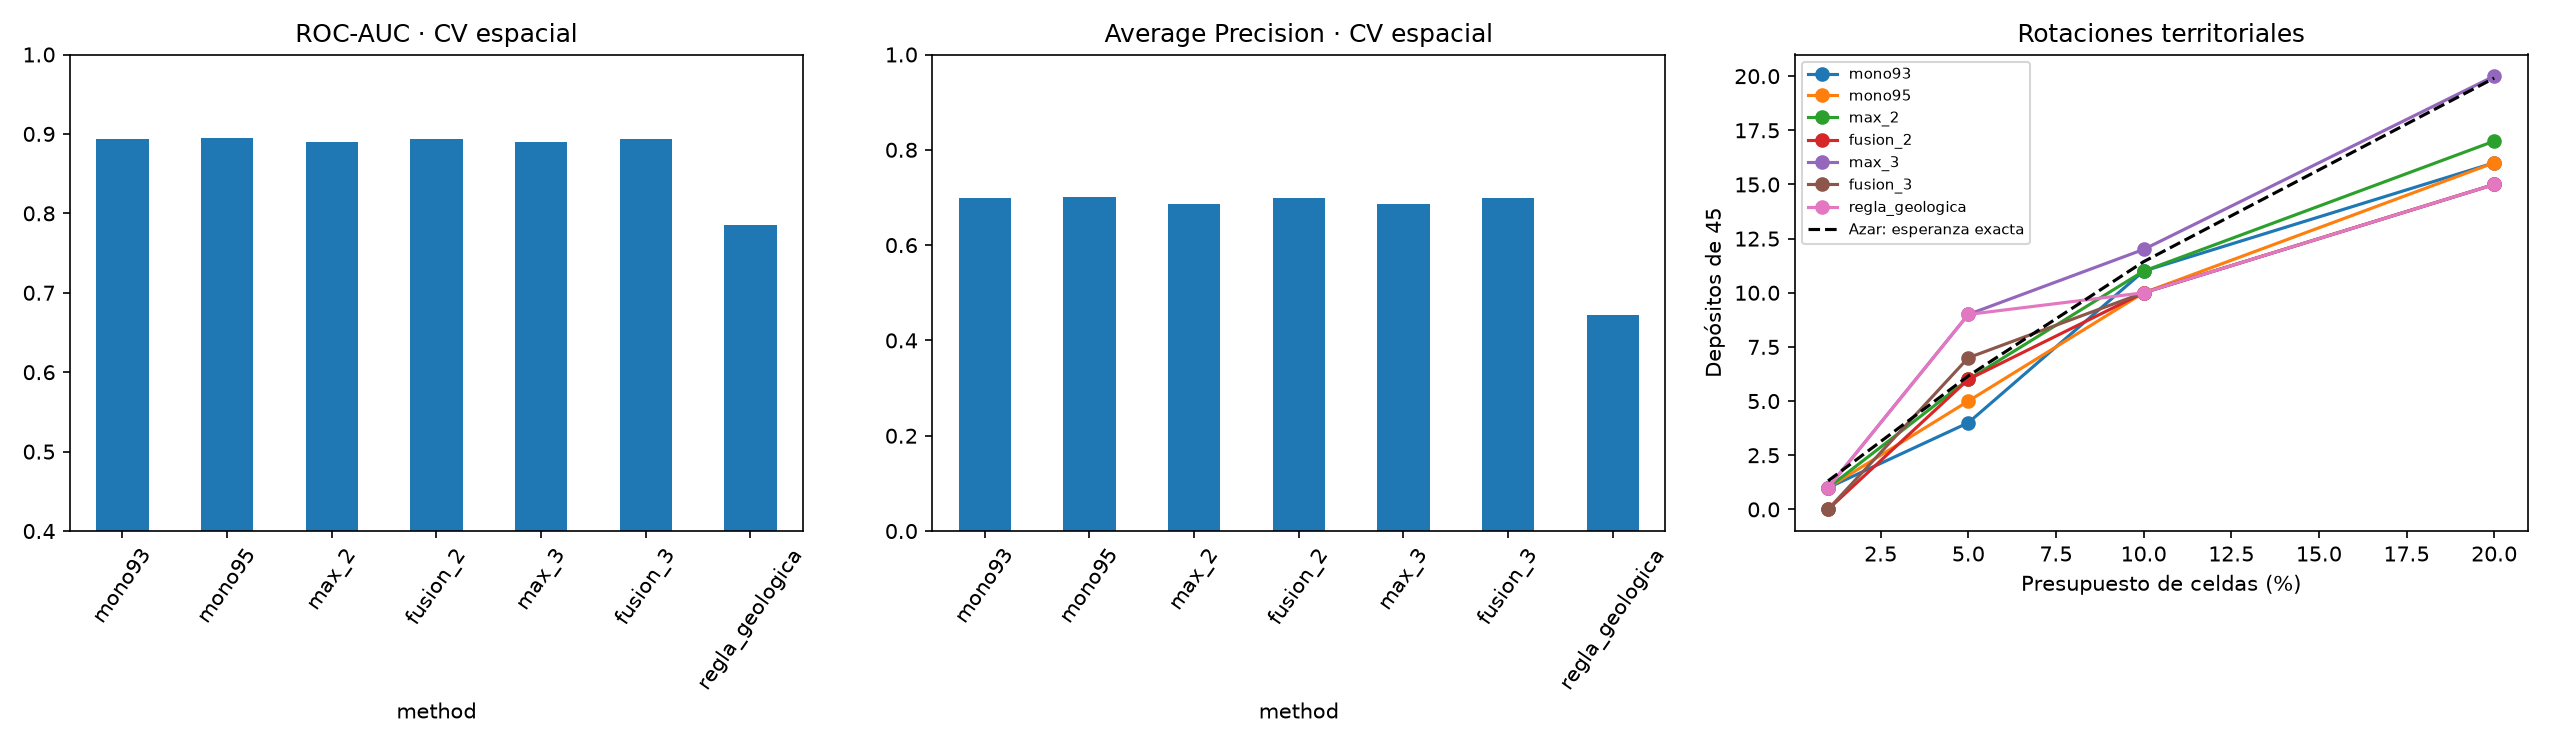

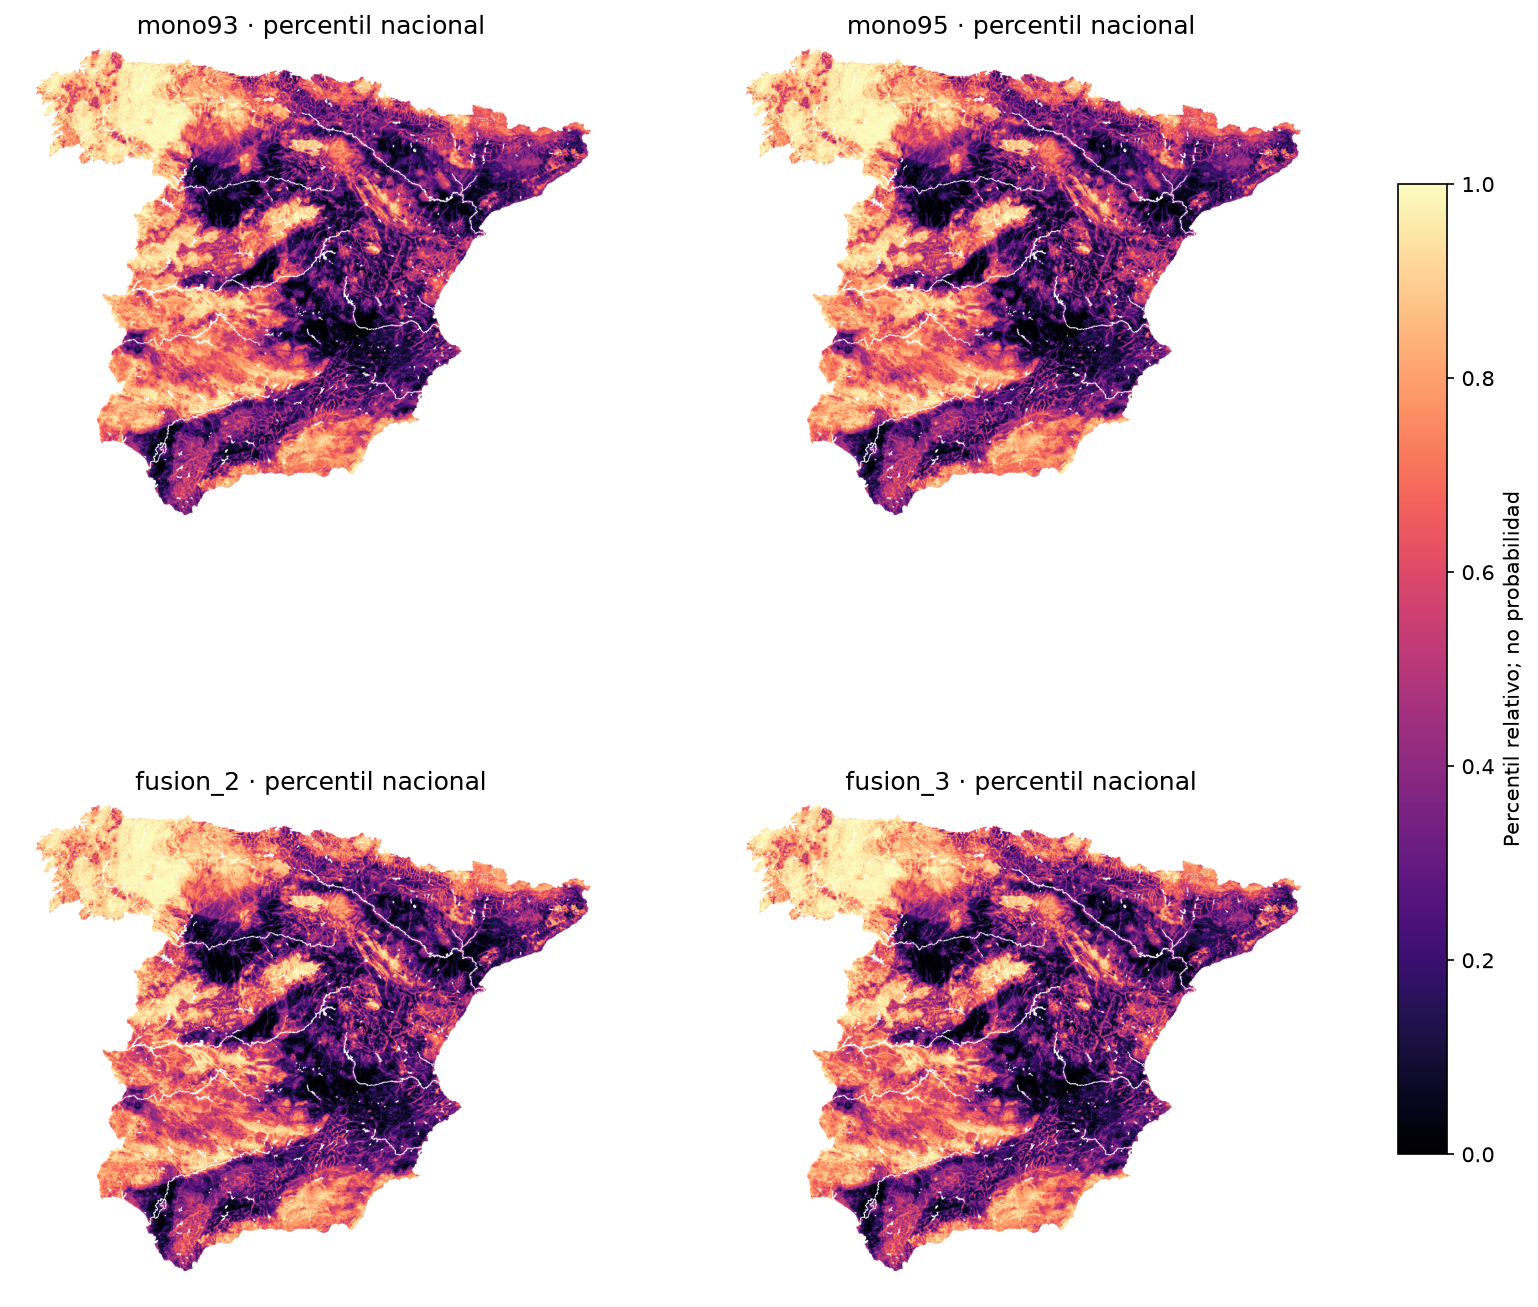

2026-10-21T23:04:33+00:00 NB27 completado y sellado; sin sustituir los resultados anteriores


# NB27 · Auditoría y comparación controlada de sistemas minerales

Experimento ejecutado el 22 de octubre de 2026. Alcance: puntos 1 a 4 de la revisión del NB26. Fuentes existentes; no se adquieren nuevas campañas ni imágenes.

## 1. Tipologías

| grupo | celdas_P |
| --- | --- |
| primario | 263 |
| primario_otro | 259 |
| aluvial | 310 |
| epitermal | 4 |
| no_resuelto | 98 |
| mixto | 7 |

Primario incluye los contextos de roca documentados; no equivale a orogénico. Epitermal se limita a los dos depósitos documentados de Rodalquilar. No se utiliza provincia, cercanía ni predicciones para asignar tipos. Los no resueltos permanecen en todos los modelos globales y en el backbone de las fusiones, sin enviarse por defecto a roca. Las celdas mixtas conservan sus etiquetas múltiples. Son reglas operativas auditables a partir del inventario; no sustituyen una nueva revisión geológica experta.

## 2. Geoquímica y covariables

La banda 2 se audita por clase y se denomina representante de intervalo, no medición analítica continua. Promediar píxeles o aplicar log1p no crea información analítica nueva. Se conservan los ausentes, se aprende la imputación dentro de cada miembro y se reconstruye la covariable MODIS de la caché sin el relleno por mediana nacional anterior. Los coeficientes del índice pathfinder se fijan antes de evaluar; sus medias y desviaciones se aprenden solo con las filas de entrenamiento. Los residuos espaciales de ventana fija son covariables de cartografía disponible, calculadas sin etiquetas. Los proxies litológicos no se presentan como mediciones de metamorfismo. Las versiones de 93 y 95 variables comparten todas estas correcciones; la única diferencia entre ellas son los dos descriptores diagnósticos del NB26.

## 3. Combinación de expertos

Ocho miembros por componente y ajuste. Las escalas se hacen comparables mediante percentiles aproximados del fondo U predicho fuera de pliegue dentro del entrenamiento, con interpolación monótona y anclas fijas 0/1. No se utiliza el mínimo o máximo del territorio evaluado, ni el factor 0,7. Estos percentiles no son probabilidades de mineralización.

`max_2` y `fusion_2` utilizan exactamente el mismo global95 y los mismos especialistas primario/aluvial. `max_3` y `fusion_3` utilizan exactamente el mismo global95 y los especialistas primario_otro/aluvial/epitermal. Solo cambia el operador de agregación. Las fusiones eligen pesos no negativos en rejilla 0,1 mediante AP interna; conservan un peso global mínimo 0,1 para las presencias no resueltas. Un especialista con menos de dos P no se entrena y se registra como no disponible: no se inventan etiquetas ni se sustituye por una regla después de observar el test. El especialista epitermal, muy escaso, usa la regularización y capacidad reducida declaradas en design.json.

## 4. Comparación controlada

Se conservan las cinco particiones espaciales de la muestra original y las siete rotaciones distritales, bloques de 50 km y buffer de 15 km. Cada entrenamiento externo realiza tres pliegues espaciales internos con buffer para construir las referencias de fondo y seleccionar los pesos. Muestreo U sin reemplazo sobre el territorio permitido tanto en CV como en rotaciones y en el ajuste nacional; siempre tres U por P y miembro. Global93 y global95 comparten exactamente filas, semillas e hiperparámetros. Se reutilizan los componentes comunes entre métodos, sin reentrenarlos con otras semillas para favorecer una opción.

Los territorios ya se han examinado en cuadernos anteriores: es una comparación interna exploratoria, no una nueva prueba ciega externa. No se selecciona un ganador nacional utilizando los resultados externos. `fusion_3` se declara antes como cartografía principal experimental y se conservan todos los demás mapas. Cada presupuesto selecciona exactamente ceil(porcentaje × celdas), con desempate por cell_id y un único recuento por depósito.

### CV espacial: misma muestra P/U

| method | roc_auc | average_precision | brier_loss | positive_cell_recovery_at_05 | positive_cell_recovery_at_10 |
| --- | --- | --- | --- | --- | --- |
| mono93 | 0.89414 | 0.69804 | 0.13112 | 0.16057 | 0.31002 |
| mono95 | 0.89490 | 0.70202 | 0.13076 | 0.15739 | 0.31161 |
| max_2 | 0.88999 | 0.68716 | 0.32241 | 0.16057 | 0.31320 |
| fusion_2 | 0.89410 | 0.69986 | 0.25552 | 0.15580 | 0.31002 |
| max_3 | 0.88999 | 0.68716 | 0.32241 | 0.16057 | 0.31320 |
| fusion_3 | 0.89410 | 0.69986 | 0.25552 | 0.15580 | 0.31002 |
| regla_geologica | 0.78513 | 0.45353 | 0.19758 | 0.08267 | 0.18601 |

AP y AUC se refieren a etiquetas P/U. Brier sobre los percentiles de las fusiones es solo un diagnóstico numérico frente a P/U: no acredita calibración física ni es un criterio para elegir entre scores con escalas diferentes.

### Recuperación de depósitos en las siete rotaciones

| method | n_deposits | captured_01 | captured_05 | captured_10 | captured_20 |
| --- | --- | --- | --- | --- | --- |
| mono93 | 45 | 1 | 4 | 11 | 16 |
| mono95 | 45 | 1 | 5 | 10 | 16 |
| max_2 | 45 | 1 | 6 | 11 | 17 |
| fusion_2 | 45 | 0 | 6 | 10 | 15 |
| max_3 | 45 | 1 | 9 | 12 | 20 |
| fusion_3 | 45 | 0 | 7 | 10 | 15 |
| regla_geologica | 45 | 1 | 9 | 10 | 15 |

Referencia aleatoria exacta, teniendo en cuenta las varias celdas de cada depósito:

| budget_percent | expected_deposits |
| --- | --- |
| 1 | 1.31547 |
| 5 | 6.16057 |
| 10 | 11.43462 |
| 20 | 19.90947 |

La regla geológica es una referencia simple predefinida de drenaje/pendiente, encajante/fallas y vulcanismo/ratios; no se ha optimizado con los territorios de evaluación. Las diferencias observadas no aíslan causalidad geológica ni garantizan significación. La comparación 93/95 aísla la incorporación de dos covariables bajo este procedimiento; 2/3 expertos compara las arquitecturas documentadas y el operador máximo/fusión sobre componentes compartidos.



Informe: C:\Users\Lenovo\Desktop\PROYECTO IA\GeoAI\GeoAI\informes\nb27_comparacion_controlada_20261022\INFORME_NB27_COMPARACION_CONTROLADA.md
Modelo nacional: C:\Users\Lenovo\Desktop\PROYECTO IA\GeoAI\GeoAI\reports\nb27_comparacion_controlada_20261022\partitions\national_0\model.joblib
Mapa experimental: C:\Users\Lenovo\Desktop\PROYECTO IA\GeoAI\GeoAI\reports\nb27_comparacion_controlada_20261022\maps\NB27_fusion3_score.tif


In [9]:
figuras = exp.make_figures()
for figura in figuras:
    display(Image(filename=str(figura)))
informe = exp.write_report()
exp.seal(informe)
display(Markdown(informe.read_text(encoding='utf-8').split('## Validación y reproducibilidad')[0].split('### Cartografía y ajuste final')[0]))
print('Informe:', informe)
print('Modelo nacional:', exp.output / 'partitions/national_0/model.joblib')
print('Mapa experimental:', exp.output / 'maps/NB27_fusion3_score.tif')
